## **FINAL EXAM DEEP LEARNING**

**NO 3**  
**Nama  : Stevanus Gerald Marconus**  
**NIM   : 2802392500**  

**LAMPIRAN:**  
Link -> https://youtu.be/gxCAwbos5nU 

### **A. Jelaskan cara kerja dari arsitektur GAN tersebut yang dideskripsikan dalam gambar.**

Generative Adversarial Network (GAN) terdiri dari dua jaringan yang saling berkompetisi (adversarial): Generator (G) yang mengubah random noise z menjadi citra palsu (fake image) untuk menipu Discriminator, dan Discriminator (D) yang bertugas membedakan citra Real (dari training set) dan Fake (dari Generator). Prosesnya berjalan bolak-balik melalui backpropagation: Generator membuat citra palsu, Discriminator menilainya Real atau Fake, lalu jika D berhasil menebak fake maka G diperbaiki agar lebih meyakinkan, sebaliknya jika D tertipu maka D diperbaiki agar lebih teliti berulang hingga citra buatan tidak bisa dibedakan dari aslinya (D menebak ~50%). Karena dataset saya memiliki 2 kelas (Storage Tank & Parking Lot), saya menggunakan Conditional GAN (cGAN), di mana G dan D sama-sama menerima label kelas melalui Embedding sebagai input tambahan (sesuai gambar arsitektur pada soal), sehingga Generator dapat menghasilkan citra sesuai kelas yang diminta.

#### **Setup & Loading Data**

In [51]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import linalg

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import spectral_norm
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split

SEED_VALUE = 1234
random.seed(SEED_VALUE); np.random.seed(SEED_VALUE)
torch.manual_seed(SEED_VALUE); torch.cuda.manual_seed_all(SEED_VALUE)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch : {torch.__version__} | Device: {device}')

PyTorch : 2.8.0+cu129 | Device: cuda


#### **LOAD DATA**

In [52]:
DATA_ROOT = '.'
TARGET_CLASSES = ['Storage Tanks', 'Parking Lot']
IMG_SIZE = 28
N_CLASSES = 2

def find_class_folders(root, target_classes):
    def norm(s): return s.lower().replace('_',' ').replace('-',' ').strip()
    def keywords(s): return frozenset(w.rstrip('s') for w in norm(s).split())
    target_kw = {keywords(c): c for c in target_classes}
    found = {}
    candidates = []
    if os.path.isdir(root):
        for item in os.listdir(root):
            full = os.path.join(root, item)
            if os.path.isdir(full) and item.lower() in ('train','test','training','testing'):
                candidates.append(full)
        candidates.append(root)
    for base in candidates:
        for d in os.listdir(base):
            full = os.path.join(base, d)
            if os.path.isdir(full) and keywords(d) in target_kw:
                found.setdefault(target_kw[keywords(d)], []).append(full)
    return found

def load_images(folder_dict, img_size=28):
    images, labels = [], []
    class_names = sorted(folder_dict.keys())
    for idx, cls in enumerate(class_names):
        for folder in folder_dict[cls]:
            for ext in ['*.png','*.jpg','*.jpeg','*.bmp']:
                for fp in glob.glob(os.path.join(folder, ext)):
                    try:
                        img = Image.open(fp).convert('L').resize((img_size,img_size))
                        images.append(np.array(img, dtype=np.float32)/255.0)
                        labels.append(idx)
                    except Exception: pass
    return np.array(images), np.array(labels), class_names

folders = find_class_folders(DATA_ROOT, TARGET_CLASSES)
X, y, class_names = load_images(folders, IMG_SIZE)
print(f'Total gambar: {len(X)} | Kelas: {class_names}')
for i,c in enumerate(class_names): print(f'  {c}: {(y==i).sum()}')

Total gambar: 16016 | Kelas: ['Parking Lot', 'Storage Tanks']
  Parking Lot: 8007
  Storage Tanks: 8009


#### **Preprocess**

##### **Scale**

In [53]:
X_scaled = X * 2.0 - 1.0

##### **Split**

In [54]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_scaled, y, test_size=0.2, random_state=SEED_VALUE, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=SEED_VALUE, stratify=y_tmp)
print(f'\nTrain: {len(X_tr)} | Val: {len(X_val)} | Test: {len(X_test)}')


Train: 12812 | Val: 1602 | Test: 1602


##### **Load to Data Loader**

In [55]:
X_tr_t = torch.tensor(X_tr, dtype=torch.float32).unsqueeze(1)
y_tr_t = torch.tensor(y_tr, dtype=torch.long)
loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=64, shuffle=True, drop_last=True)

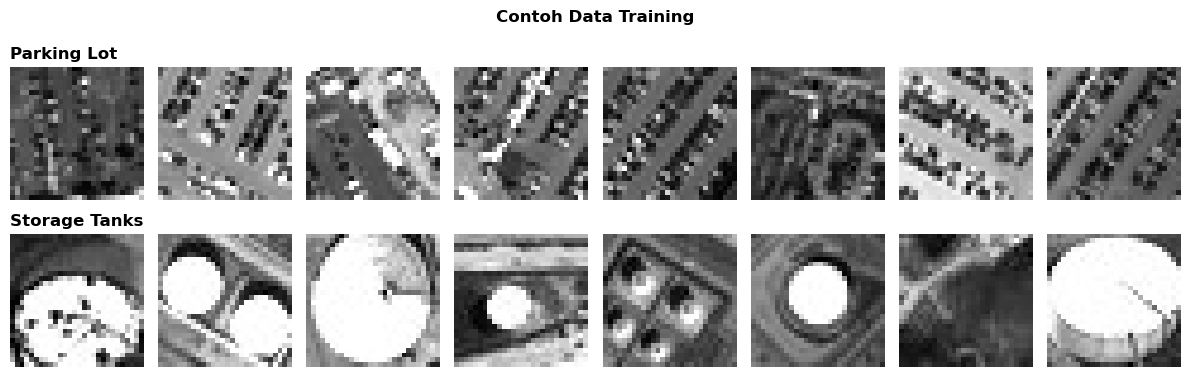

In [56]:
plt.figure(figsize=(12,4))
for r in range(N_CLASSES):
    idxs = np.where(y_tr==r)[0][:8]
    for c, idx in enumerate(idxs):
        plt.subplot(N_CLASSES, 8, r*8+c+1); plt.imshow((X_tr[idx]+1)/2, cmap='gray'); plt.axis('off')
        if c==0: plt.title(class_names[r], loc='left', fontweight='bold')
plt.suptitle('Contoh Data Training', fontweight='bold'); plt.tight_layout(); plt.show()

### **B. Buatlah arsitektur untuk image generation sesuai dengan gambar arsitektur GAN. Lakukan evaluasi kesamaan distribusi citra dengan menggunakan Fréchet Inception Distance (FID) pada data test.**

#### **B.1 Model 1 (Baseline Conditional GAN) Arsitektur**

In [57]:
LATENT_DIM = 100

class Generator(nn.Module):
    def __init__(self, latent=100, n_classes=2, img_size=28):
        super().__init__()
        self.img_size = img_size
        self.label_emb = nn.Embedding(n_classes, n_classes)
        def block(i, o, bn=True):
            layers = [nn.Linear(i, o)]
            if bn: layers.append(nn.BatchNorm1d(o, 0.8))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers
        self.model = nn.Sequential(
            *block(latent + n_classes, 128, bn=False),
            *block(128, 256), *block(256, 512), *block(512, 1024),
            nn.Linear(1024, img_size*img_size), nn.Tanh())
    def forward(self, noise, labels):
        x = torch.cat([noise, self.label_emb(labels)], dim=1)
        return self.model(x).view(x.size(0), 1, self.img_size, self.img_size)

class Discriminator(nn.Module):
    def __init__(self, n_classes=2, img_size=28):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, n_classes)
        self.model = nn.Sequential(
            nn.Linear(n_classes + img_size*img_size, 512), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2, inplace=True), nn.Dropout(0.4),
            nn.Linear(1024, 512), nn.LeakyReLU(0.2, inplace=True), nn.Dropout(0.4),
            nn.Linear(512, 1), nn.Sigmoid())
    def forward(self, img, labels):
        x = torch.cat([img.view(img.size(0), -1), self.label_emb(labels)], dim=1)
        return self.model(x)

G = Generator(LATENT_DIM, N_CLASSES, IMG_SIZE).to(device)
D = Discriminator(N_CLASSES, IMG_SIZE).to(device)
print(f'Generator params     : {sum(p.numel() for p in G.parameters()):,}')
print(f'Discriminator params : {sum(p.numel() for p in D.parameters()):,}')

Generator params     : 1,510,292
Discriminator params : 1,453,573


#### **B.2 Model 1 Training**

In [58]:
def train_gan(G, D, loader, epochs=100, lr=2e-4, latent=100, smooth=False):
    adv_loss = nn.BCELoss()
    opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    hist = {'g_loss': [], 'd_loss': []}
    for ep in range(epochs):
        ge, de, nb = 0, 0, 0
        for real_imgs, labels in loader:
            bs = real_imgs.size(0)
            real_imgs, labels = real_imgs.to(device), labels.to(device)
            valid = torch.full((bs,1), 0.9 if smooth else 1.0, device=device)
            fake  = torch.zeros(bs, 1, device=device)
            
            opt_G.zero_grad()
            z = torch.randn(bs, latent, device=device)
            gl = torch.randint(0, N_CLASSES, (bs,), device=device)
            gen = G(z, gl)
            g_loss = adv_loss(D(gen, gl), torch.ones(bs,1,device=device))
            g_loss.backward(); opt_G.step()
           
            opt_D.zero_grad()
            d_loss = (adv_loss(D(real_imgs, labels), valid) + adv_loss(D(gen.detach(), gl), fake)) / 2
            d_loss.backward(); opt_D.step()
            ge += g_loss.item(); de += d_loss.item(); nb += 1
        hist['g_loss'].append(ge/nb); hist['d_loss'].append(de/nb)
        if (ep+1)%10==0 or ep==0: print(f'  Epoch {ep+1:3d}/{epochs} | G_loss={ge/nb:.4f} | D_loss={de/nb:.4f}')
    return hist

In [59]:
print(f"Training Model 1 (Baseline cGAN)")
history_model1 = train_gan(G, D, loader, epochs=100)

Training Model 1 (Baseline cGAN)
  Epoch   1/100 | G_loss=1.3348 | D_loss=0.4604
  Epoch  10/100 | G_loss=1.5351 | D_loss=0.4478
  Epoch  20/100 | G_loss=1.3038 | D_loss=0.4933
  Epoch  30/100 | G_loss=1.2402 | D_loss=0.5010
  Epoch  40/100 | G_loss=1.1790 | D_loss=0.5240
  Epoch  50/100 | G_loss=1.1293 | D_loss=0.5390
  Epoch  60/100 | G_loss=1.1143 | D_loss=0.5399
  Epoch  70/100 | G_loss=1.0471 | D_loss=0.5726
  Epoch  80/100 | G_loss=1.0950 | D_loss=0.5590
  Epoch  90/100 | G_loss=1.0548 | D_loss=0.5662
  Epoch 100/100 | G_loss=1.0178 | D_loss=0.5759


In [60]:
def plot_gan_loss(hist, title):
    plt.figure(figsize=(10,5))
    plt.plot(hist['g_loss'], label='Generator', color='teal', linewidth=2)
    plt.plot(hist['d_loss'], label='Discriminator', color='orange', linewidth=2)
    plt.title(f'{title} – Adversarial Loss', fontsize=14, fontweight='bold')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

def show_generated(G, n=8, latent=100, title='Generated Images'):
    G.eval()
    plt.figure(figsize=(n*1.5, N_CLASSES*1.8))
    with torch.no_grad():
        for cls in range(N_CLASSES):
            z = torch.randn(n, latent, device=device)
            labels = torch.full((n,), cls, dtype=torch.long, device=device)
            gen = G(z, labels).cpu().numpy()
            for i in range(n):
                plt.subplot(N_CLASSES, n, cls*n+i+1)
                plt.imshow((gen[i,0]+1)/2, cmap='gray'); plt.axis('off')
                if i==0: plt.title(class_names[cls], loc='left', fontweight='bold')
    plt.suptitle(title, fontweight='bold'); plt.tight_layout(); plt.show()
    G.train()

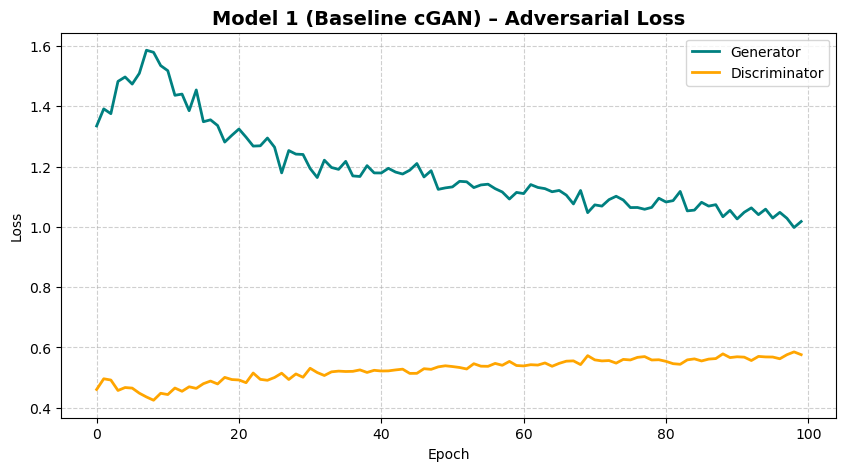

In [61]:
plot_gan_loss(history_model1, 'Model 1 (Baseline cGAN)')

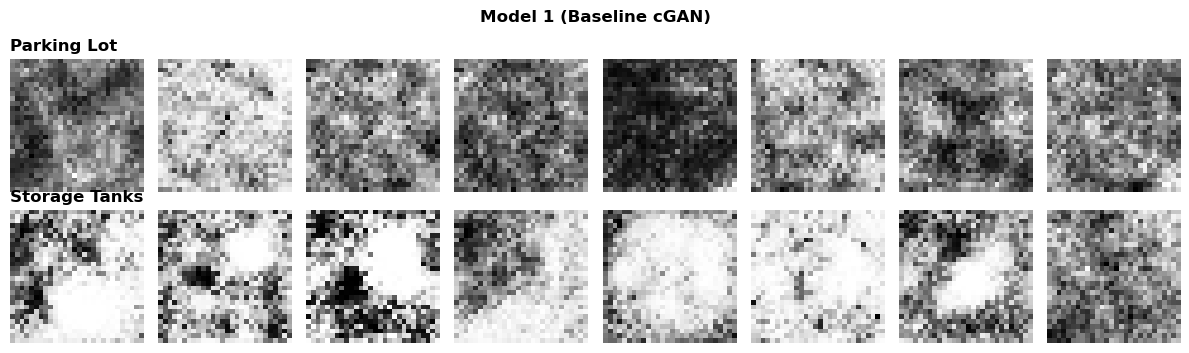

In [62]:
show_generated(G, title='Model 1 (Baseline cGAN)')

#### **B.3 Evaluasi FID Model 1**

In [63]:
from torchvision.models import inception_v3

def get_inception():
    model1 = inception_v3(weights='IMAGENET1K_V1', transform_input=False)
    model1.fc = nn.Identity()
    return model1.eval().to(device)

def extract_features(inception, images, batch=32):
    feats = []
    with torch.no_grad():
        for i in range(0, len(images), batch):
            b = images[i:i+batch].to(device)
            b = (b + 1) / 2
            b = b.repeat(1, 3, 1, 1)
            b = F.interpolate(b, size=(299,299), mode='bilinear', align_corners=False)
            mean = torch.tensor([0.485,0.456,0.406], device=device).view(1,3,1,1)
            std  = torch.tensor([0.229,0.224,0.225], device=device).view(1,3,1,1)
            b = (b - mean) / std
            feats.append(inception(b).cpu().numpy())
    return np.concatenate(feats, axis=0)

def calculate_fid(feat_real, feat_fake):
    mu1, sigma1 = feat_real.mean(0), np.cov(feat_real, rowvar=False)
    mu2, sigma2 = feat_fake.mean(0), np.cov(feat_fake, rowvar=False)
    diff = np.sum((mu1 - mu2)**2)
    covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(diff + np.trace(sigma1 + sigma2 - 2*covmean))

def evaluate_fid(G, X_test, inception, latent=100, label='Model'):
    G.eval()
    n = len(X_test)
    real_t = torch.tensor(X_test[:n], dtype=torch.float32).unsqueeze(1)
    with torch.no_grad():
        z = torch.randn(n, latent, device=device)
        labels = torch.randint(0, N_CLASSES, (n,), device=device)
        fake_t = G(z, labels).cpu()
    fr = extract_features(inception, real_t); ff = extract_features(inception, fake_t)
    fid = calculate_fid(fr, ff)
    print(f'  {label}: FID = {fid:.4f}')
    G.train(); return fid

print('Memuat InceptionV3...')
inception = get_inception()
fid_model1 = evaluate_fid(G, X_test, inception, label='Model 1 (Baseline)')

Memuat InceptionV3...


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_21908\3629479426.py:26: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


  Model 1 (Baseline): FID = 271.3636


Pada model baseline (MLP cGAN), Generator sudah mampu menghasilkan citra yang menyerupai kelas Storage Tank dan Parking Lot. Nilai **FID** mengukur jarak antara distribusi fitur (dari InceptionV3) citra asli dan citra generated semakin kecil FID, semakin mirip distribusinya. Karena arsitektur baseline menggunakan layer Linear (fully-connected), hasilnya masih cenderung kasar dan kurang tajam.

### **C. Setelah mengetahui hasil dari nomor (3b), modifikasi arsitektur GAN di atas agar mendapatkan metrik Fréchet Inception Distance (FID) yang lebih baik.**

#### **C.1 Model 2 (Modified DCGAN-Conditional) Arsitektur**

In [64]:
class ModGenerator(nn.Module):
    def __init__(self, latent=100, n_classes=2, img_size=28):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, n_classes)
        self.init_size = img_size // 4
        self.l1 = nn.Linear(latent + n_classes, 128 * self.init_size**2)
        self.conv_blocks = nn.Sequential(
            nn.BatchNorm2d(128), nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128, 0.8), nn.LeakyReLU(0.2),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, padding=1), nn.BatchNorm2d(64, 0.8), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 1, 3, padding=1), nn.Tanh())
    def forward(self, noise, labels):
        x = torch.cat([noise, self.label_emb(labels)], dim=1)
        x = self.l1(x).view(x.size(0), 128, self.init_size, self.init_size)
        return self.conv_blocks(x)

class ModDiscriminator(nn.Module):
    def __init__(self, n_classes=2, img_size=28):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, n_classes)
        def block(i, o, bn=True):
            b = [nn.Conv2d(i, o, 3, 2, 1), nn.LeakyReLU(0.2), nn.Dropout2d(0.25)]
            if bn: b.append(nn.BatchNorm2d(o, 0.8))
            return b
        self.conv = nn.Sequential(*block(1,16,bn=False), *block(16,32), *block(32,64))
        self.adv = nn.Sequential(nn.Linear(64*4*4 + n_classes, 1), nn.Sigmoid())
    def forward(self, img, labels):
        f = self.conv(img).view(img.size(0), -1)
        return self.adv(torch.cat([f, self.label_emb(labels)], dim=1))

def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.constant_(m.bias, 0)

G2 = ModGenerator(LATENT_DIM, N_CLASSES, IMG_SIZE).to(device)
D2 = ModDiscriminator(N_CLASSES, IMG_SIZE).to(device)
G2.apply(weights_init); D2.apply(weights_init)
print(f'Modified G params: {sum(p.numel() for p in G2.parameters()):,}')
print(f'Modified D params: {sum(p.numel() for p in D2.parameters()):,}')

Modified G params: 868,613
Modified D params: 24,519


#### **C.2 Model 2 Training (dengan Label Smoothing)**

In [65]:
print('Training Model 2 (Modified DCGAN-cGAN)...')
history_model2 = train_gan(G2, D2, loader, epochs=100, smooth=True)

Training Model 2 (Modified DCGAN-cGAN)...
  Epoch   1/100 | G_loss=0.7788 | D_loss=0.6891
  Epoch  10/100 | G_loss=0.8004 | D_loss=0.6872
  Epoch  20/100 | G_loss=0.7986 | D_loss=0.6883
  Epoch  30/100 | G_loss=0.7991 | D_loss=0.6884
  Epoch  40/100 | G_loss=0.7978 | D_loss=0.6880
  Epoch  50/100 | G_loss=0.7983 | D_loss=0.6884
  Epoch  60/100 | G_loss=0.7983 | D_loss=0.6883
  Epoch  70/100 | G_loss=0.7979 | D_loss=0.6885
  Epoch  80/100 | G_loss=0.7986 | D_loss=0.6880
  Epoch  90/100 | G_loss=0.7985 | D_loss=0.6881
  Epoch 100/100 | G_loss=0.8018 | D_loss=0.6866


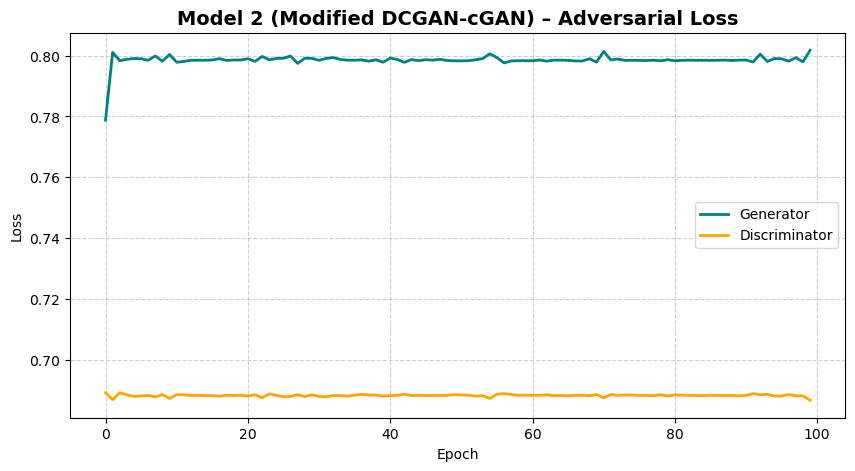

In [66]:
plot_gan_loss(history_model2, 'Model 2 (Modified DCGAN-cGAN)')

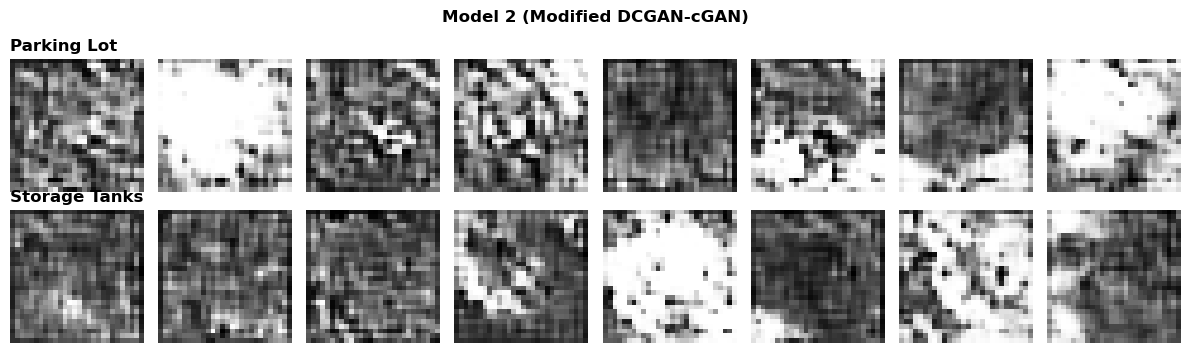

In [67]:
show_generated(G2, title='Model 2 (Modified DCGAN-cGAN)')

#### **C.3 Evaluasi & Perbandingan FID**

In [68]:
fid_model2 = evaluate_fid(G2, X_test, inception, label='Model 2 (Modified)')

import pandas as pd
df_fid = pd.DataFrame({
    'Model': ['Model 1 (Baseline MLP)', 'Model 2 (Modified DCGAN)'],
    'FID': [fid_model1, fid_model2]
})
df_fid['Peningkatan'] = ['—', f'{(fid_model1-fid_model2):.2f} lebih rendah ({(fid_model1-fid_model2)/fid_model1*100:+.1f}%)']
display(df_fid.set_index('Model').style.format({'FID':'{:.4f}'})
    .set_caption('Perbandingan FID – Semakin kecil semakin baik'))

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_21908\3629479426.py:26: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


  Model 2 (Modified): FID = 198.5660


,FID,Peningkatan
Model,,
Model 1 (Baseline MLP),271.3636,—
Model 2 (Modified DCGAN),198.5660,72.80 lebih rendah (+26.8%)
